In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

finance1 = pd.read_excel("/content/Finance_1 - Finance_1.xlsx")
finance2 = pd.read_excel("/content/Finance_2.xlsx - Sheet1.xlsx")

print(finance1.shape)
print(finance2.shape)

print(finance1.columns)
print(finance2.columns)

(39717, 24)
(39717, 25)
Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'desc', 'purpose', 'title',
       'zip_code', 'addr_state', 'dti'],
      dtype='object')
Index(['id', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt',
       'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
       'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
       'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d',
       'last_credit_pull_d'],
      dtype='object')


In [ ]:
##COUNT MISSING VALUES IN EACH COLUMN FOR BOTH DATA SET

finance1.isnull().sum()


,0
id,0
member_id,0
loan_amnt,0
funded_amnt,0
funded_amnt_inv,0
term,0
int_rate,0
installment,0
grade,0
sub_grade,0


In [ ]:
finance2.isnull().sum()

,0
id,0
delinq_2yrs,0
earliest_cr_line,0
inq_last_6mths,0
mths_since_last_delinq,25682
mths_since_last_record,36931
open_acc,0
pub_rec,0
revol_bal,0
revol_util,50


In [ ]:
## REPLCE emp_title	emp_length IN TO "UNKNOWN"

finance1['emp_title']=finance1['emp_title'].fillna('unknown')

finance1['emp_length']=finance1['emp_length'].fillna('unkown')

In [ ]:
## CONVERT ISSUE_D TO DATE

#contains dates. We convert them into a proper date format

finance1['issue_d'] = pd.to_datetime(finance1['issue_d'])

In [ ]:
##CREATE YEAR

#This takes only the year from the date.

finance1['year'] = finance1['issue_d'].dt.year

In [ ]:
## YEAR WISE LOAN AMOUNT

year = finance1.groupby('year')['loan_amnt'].sum()
print(year)

year
2026    445602650
Name: loan_amnt, dtype: int64


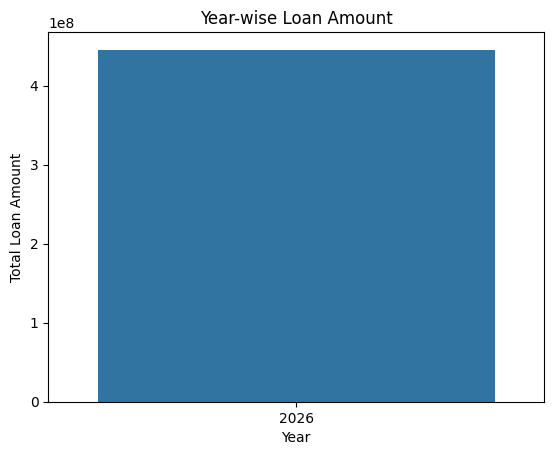

In [ ]:
year_loan = year.reset_index()

sns.barplot(data=year_loan, x='year', y='loan_amnt')

plt.title('Year-wise Loan Amount')
plt.xlabel('Year')
plt.ylabel('Total Loan Amount')
plt.show()

In [ ]:
## GRADE & SUB-GRADE WISE REVOLVING BALANCE



finance = pd.merge(finance1, finance2, on='id')

grade_revol = (finance.groupby(['grade', 'sub_grade'])['revol_bal'].sum().reset_index())

print(grade_revol)


   grade sub_grade  revol_bal
0      A        A1   11365196
1      A        A2   14004780
2      A        A3   19543922
3      A        A4   34557156
4      A        A5   35303045
5      B        B1   21842079
6      B        B2   26478439
7      B        B3   39723554
8      B        B4   35405811
9      B        B5   37858666
10     C        C1   29384926
11     C        C2   27321114
12     C        C3   20531370
13     C        C4   16867691
14     C        C5   16015609
15     D        D1   12130255
16     D        D2   18570972
17     D        D3   16793781
18     D        D4   13742947
19     D        D5   13252474
20     E        E1   11132588
21     E        E2   10242033
22     E        E3    9039059
23     E        E4    7990991
24     E        E5    7669868
25     F        F1    5840746
26     F        F2    4528248
27     F        F3    3175435
28     F        F4    2551064
29     F        F5    2187323
30     G        G1    1808763
31     G        G2    1729627
32     G  

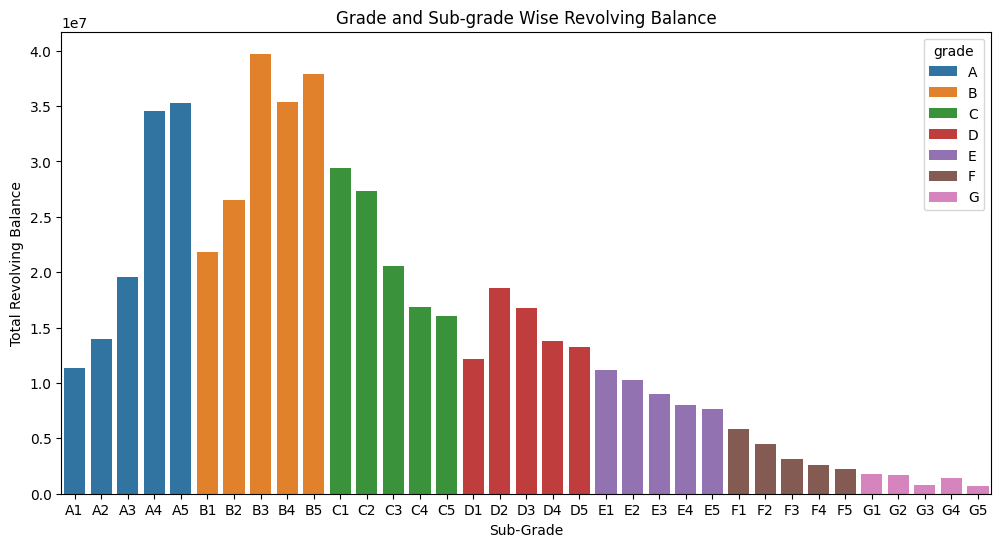

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(data=grade_revol,x='sub_grade',y='revol_bal',hue ='grade')

plt.title('Grade and Sub-grade Wise Revolving Balance')
plt.xlabel('Sub-Grade')
plt.ylabel('Total Revolving Balance')
plt.show()

In [ ]:
## TOTAL PAYMENT- VERIFIED & NON VERIFIED

payment_status = (finance.groupby('verification_status')['total_pymnt'].sum().reset_index())

print(payment_status)

  verification_status   total_pymnt
0        Not Verified  1.535414e+08
1     Source Verified  1.092707e+08
2            Verified  2.198923e+08


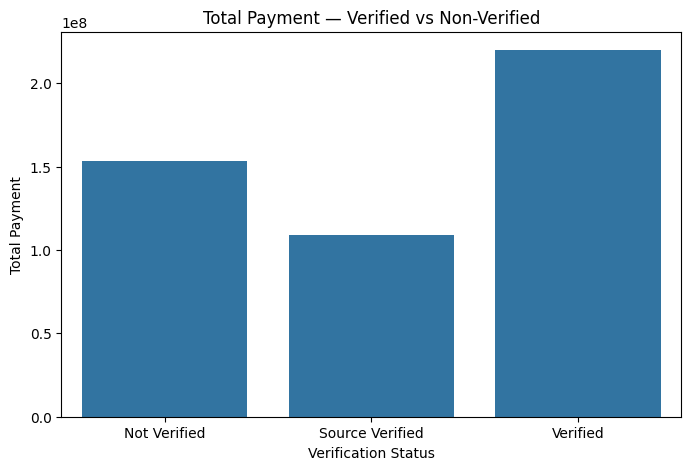

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=payment_status,x='verification_status',y='total_pymnt')

plt.title('Total Payment — Verified vs Non-Verified')
plt.xlabel('Verification Status')
plt.ylabel('Total Payment')
plt.show()

In [ ]:
## STATE WISE & MONTH WISE LOAN STATUS

# .size() = count

#.reset_index() = make it a table

#name='loan_count' = give the count column a name

month=finance1['month'] = finance1['issue_d'].dt.month_name()
month

state_month_status = (finance1.groupby(['addr_state', 'month', 'loan_status']).size().reset_index(name='loan_count'))

print(state_month_status)

     addr_state      month  loan_status  loan_count
0            AK      April  Charged Off           1
1            AK      April   Fully Paid           3
2            AK     August  Charged Off           1
3            AK     August   Fully Paid           4
4            AK   December  Charged Off           4
...         ...        ...          ...         ...
1274         WY   November   Fully Paid           4
1275         WY    October  Charged Off           1
1276         WY    October   Fully Paid          11
1277         WY  September  Charged Off           2
1278         WY  September   Fully Paid           5

[1279 rows x 4 columns]


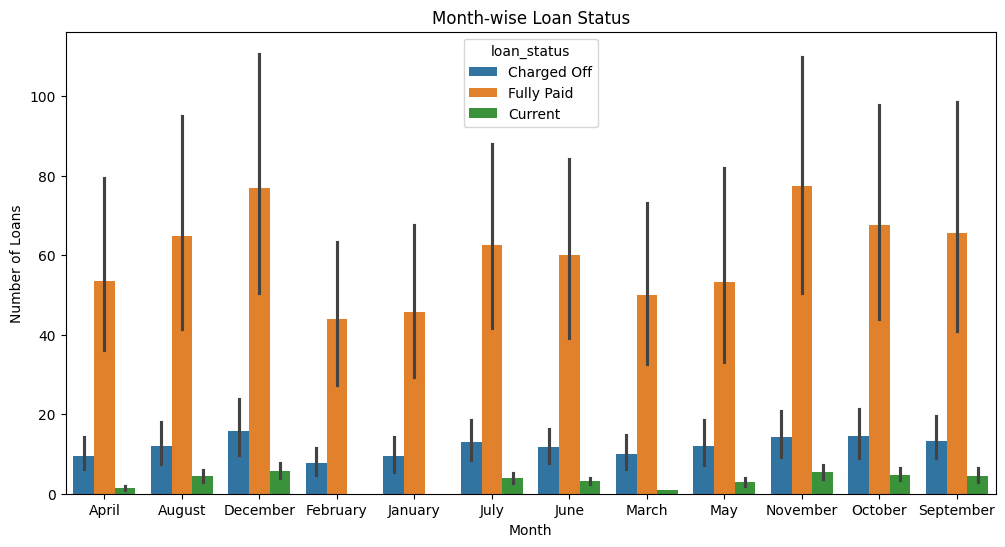

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(data=state_month_status,x='month',y='loan_count',hue='loan_status')

plt.title('Month-wise Loan Status')
plt.xlabel('Month')
plt.ylabel('Number of Loans')
plt.show()

In [ ]:
## HOME OWNERSHIP VS LAST PAYMENT DATE

finance['last_pymnt_d'] = pd.to_datetime(finance['last_pymnt_d'])

home_payment = (finance.groupby('home_ownership')['last_pymnt_d'].count().reset_index(name='payment_count'))

print(home_payment)

  home_ownership  payment_count
0       MORTGAGE          17645
1           NONE              3
2          OTHER             98
3            OWN           3053
4           RENT          18847


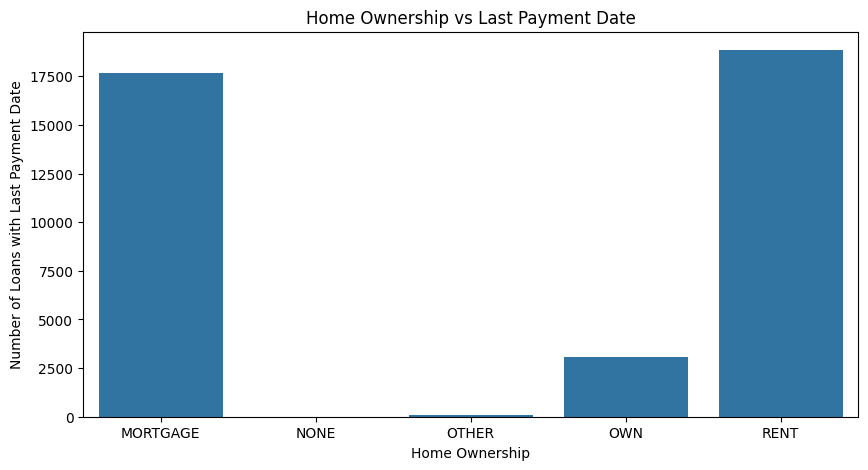

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(data=home_payment,x='home_ownership',y='payment_count')

plt.title('Home Ownership vs Last Payment Date')
plt.xlabel('Home Ownership')
plt.ylabel('Number of Loans with Last Payment Date')

plt.show()